# CoverWise AI - dataset profiling and scoring-model review
Reproduces the key checks behind the shipped risk scorer: data quality, the leakage finding, the model comparison and a worked example. Run from the repository root after `python scripts/train_model.py`.

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
import matplotlib.pyplot as plt
from coverwise.scoring import score_to_label, RULE_WEIGHTS

df = pd.read_csv(ROOT / "data/raw/coverwise_synthetic_coverage_risk_dataset_500.csv")
print(df.shape)
df.risk_label.value_counts()

(500, 21)


risk_label
Moderate Coverage    181
Strong Coverage      176
Caution Required     110
High Risk             33
Name: count, dtype: int64

## 1. Data quality
No nulls or duplicates; the label is almost a function of the score bands, and some rows are logically inconsistent.

In [2]:
print("nulls:", int(df.isna().sum().sum()), "| duplicate ids:", int(df.policy_id.duplicated().sum()))
print("label == score band:", round((df.risk_label == df.coverage_clarity_score.map(score_to_label)).mean(), 3))
print("PED waiting < initial waiting:", int((df.pre_existing_disease_waiting_period_months < df.waiting_period_months).sum()), "rows")
print(
    "maternity on Top-up / Critical Illness / Senior:",
    int((df.maternity_coverage_present.eq(1) & df.policy_type.isin(["Top-up Health", "Critical Illness", "Senior Citizen"])).sum()),
    "rows",
)

nulls: 0 | duplicate ids: 0
label == score band: 0.966
PED waiting < initial waiting: 168 rows
maternity on Top-up / Critical Illness / Senior: 20 rows


## 2. What drives the score? (and why `risk_flags_count` is excluded)

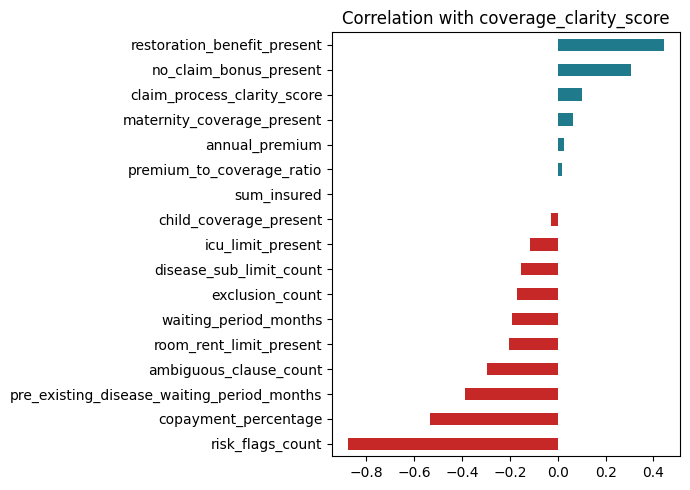

risk_flags_count correlation: -0.88 -> derived from other features, excluded from the production model


In [3]:
num = df.select_dtypes("number").drop(columns="coverage_clarity_score")
corr = num.corrwith(df.coverage_clarity_score).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
corr.plot.barh(ax=ax, color=["#c62828" if v < 0 else "#1f7a8c" for v in corr])
ax.set_title("Correlation with coverage_clarity_score")
plt.tight_layout()
plt.show()
print("risk_flags_count correlation:", round(corr["risk_flags_count"], 2), "-> derived from other features, excluded from the production model")

## 3. Model comparison (5-fold out-of-fold, from `models/metrics.json`)

In [4]:
m = json.loads((ROOT / "models/metrics.json").read_text())
table = pd.DataFrame(m["classifiers"]).T[["accuracy", "macro_f1"]].round(3).sort_values("macro_f1")
display(table)
print("Production method:", m["production_method"])
print("Per-class (production):")
display(pd.DataFrame(m["per_class_production"]).T[["precision", "recall", "f1-score", "support"]])

,accuracy,macro_f1
Decision Tree | core (no risk_flags_count),0.473,0.424
Random Forest | core (no risk_flags_count),0.625,0.473
Gradient Boosting | core (no risk_flags_count),0.650,0.550
Random Forest | with risk_flags_count,0.790,0.636
Decision Tree | with risk_flags_count,0.765,0.702
Gradient Boosting | with risk_flags_count,0.806,0.727
Logistic Regression | core (no risk_flags_count),0.762,0.730
Ridge regressor -> score bands | core,0.804,0.772
Rule-based baseline,0.817,0.793
Gradient Boosting regressor -> score bands | core,0.812,0.798


Production method: Gradient Boosting regressor -> score bands
Per-class (production):


,precision,recall,f1-score,support
High Risk,0.905,0.633,0.745,30.0
Caution Required,0.814,0.790,0.802,105.0
Moderate Coverage,0.756,0.844,0.798,180.0
Strong Coverage,0.872,0.824,0.847,165.0


## 4. Transparent rule weights (rounded from a linear fit; used for the reasons shown to users)

In [5]:
pd.DataFrame([(label, w) for _, (w, label) in RULE_WEIGHTS.items()], columns=["factor", "points per unit"]).sort_values("points per unit")

,factor,points per unit
3,Room rent capped,-7.00
4,ICU charges capped,-7.00
10,Ambiguous / unclear clauses (each),-3.70
5,Disease-wise sub-limits (each),-1.70
0,Co-payment (per %),-1.00
6,Listed exclusions (each),-0.50
1,Pre-existing disease waiting (per month),-0.40
2,Specific/initial waiting (per month),-0.20
9,Claim process clarity (per point),0.13
11,Maternity covered,1.50


## 5. Worked example on the bundled fictional policy

In [6]:
from coverwise.pipeline import analyze, load_policy, sample_paths
from coverwise.scoring import ScoringModel
from coverwise.config import SAMPLES_DIR

cur, new = sample_paths(SAMPLES_DIR)
a = analyze(load_policy("Current", cur), model=ScoringModel.load())
print(a["score"]["score"], a["score"]["label"])
display(pd.DataFrame(a["score"]["reasons"]))
for f in a["flags"][:4]:
    print(f["severity"].upper(), "-", f["title"])

33.9 High Risk


,factor,value,points
0,Restoration / recharge benefit,0,-11.2
1,ICU charges capped,1,-5.5
2,Pre-existing disease waiting (per month),36,-5.4
3,Room rent capped,1,-4.5
4,Disease-wise sub-limits (each),4,-3.7
5,Ambiguous / unclear clauses (each),3,-3.3
6,Co-payment (per %),10,-2.4
7,Specific/initial waiting (per month),24,-2.1
8,No-claim bonus,1,4.1
9,Claim process clarity (per point),100,4.1


MEDIUM - Co-payment of 10%
MEDIUM - Pre-existing disease waiting period of 36 months
MEDIUM - Specific-disease waiting period of 24 months
MEDIUM - Room rent is capped


**Take-aways.** Rules matched ML on this small synthetic set; tree classifiers overfit; the derived `risk_flags_count` inflates results and is excluded; High Risk recall (0.63) is the weak spot. Real-world validity needs human-reviewed real policies (see the optional human-review module).